# 03.1 — Preparação de Dados
**Depende de:** dados brutos em data/gestante_quadro_clinico.parquet
**Salva em:** out/artifacts/ e out/03.1_preparacao/

In [1]:
from __future__ import annotations

import json
import pickle
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "en"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "fill_ylabel":       "Fill rate no treino (%)",
        "fill_title_fmt":    "Cobertura das Features — Fill Rate no Conjunto de Treino\n{extra}",
        "fill_adm_lbl":      "admissao",
        "fill_pos_lbl":      "pós-atendimento",
        "fill_50_lbl":       "50%",
        "fill_80_lbl":       "80%",
        "dist_title":        "Distribuições — Features Numéricas de Admissão (Treino)",
        "split_treino":      "Treino",
        "split_valid":       "Validação",
        "split_teste":       "Teste",
        "split_ylabel":      "Fill rate (%)",
        "split_title":       "Fill Rate por Split — Top 30 features mais preenchidas",
        "split_80_lbl":      "80%",
    },
    "en": {
        "fill_ylabel":       "Fill rate in training set (%)",
        "fill_title_fmt":    "Feature Coverage — Fill Rate in Training Set\n{extra}",
        "fill_adm_lbl":      "admission",
        "fill_pos_lbl":      "post-attendance",
        "fill_50_lbl":       "50%",
        "fill_80_lbl":       "80%",
        "dist_title":        "Distributions — Numeric Admission Features (Training)",
        "split_treino":      "Training",
        "split_valid":       "Validation",
        "split_teste":       "Test",
        "split_ylabel":      "Fill rate (%)",
        "split_title":       "Fill Rate by Split — Top 30 most-filled features",
        "split_80_lbl":      "80%",
    },
}
T = _T[LANG]

# Paths
ROOT     = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "out" / "03.1_preparacao"
PLOT_DIR = OUT_DIR / "plots"
ART_DIR  = ROOT / "out" / "artifacts"   # shared state between sub-files

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

print('------')
print(ROOT)
print(DATA_DIR)

PARQUET = DATA_DIR / "gestante_quadro_clinico.parquet"
print(f"Parquet : {PARQUET} ({PARQUET.stat().st_size/1e6:.1f} MB)")
print(f"Saída   : {OUT_DIR}")

## 1. Carga e Feature Engineering

In [2]:
df = pd.read_parquet(PARQUET)
df.columns = df.columns.str.lower()
df = df[df["is_recem_nascido"] == 0].copy()  # exclui RN
print(f"Gestantes (sem RN): {len(df):,}")
df.columns = df.columns.str.lower()
print(f"Shape: {df.shape}")

# Datas
for col in ["dt_atendimento", "dt_alta", "dt_nascimento", "dt_retorno",
            "dt_parto", "dh_triagem", "dh_primeira_evolucao"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

df["ano"] = df["dt_atendimento"].dt.year
df["mes"] = df["dt_atendimento"].dt.month
df["hora_admissao"] = df["dt_atendimento"].dt.hour

# ── Targets ────────────────────────────────────────────────────────────────
def to_bin(s, pos="S"):
    return (s.fillna("N").astype(str).str.upper() == pos).astype(int)

df["y_retorno_30d"]     = to_bin(df["sn_retorno_30d"])
df["y_retorno_90d"]     = to_bin(df["sn_retorno_90d"])
df["y_obito_materno"]   = to_bin(df["sn_obito"])
df["y_desfecho_grave"]  = (
    (df["y_obito_materno"] == 1) |
    (pd.to_numeric(df["qtd_obito_neonatal"], errors="coerce").fillna(0) > 0)
).astype(int)

TARGETS = {
    "y_retorno_30d":    "Retorno 30d (primário)",
    "y_retorno_90d":    "Retorno 90d",
    "y_obito_materno":  "Óbito Materno",
    "y_desfecho_grave": "Desfecho Grave (óbito mat. ou neonatal)",
}


# Criando o sumário de completude
df_summary = pd.DataFrame({
    'Tipo': df.dtypes,
    'Não Nulos': df.count(),
    'Nulos': df.isnull().sum(),
    '% Preenchimento': (df.count() / len(df)) * 100
}).sort_index()

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print("\n" + "="*80)
    print(f"RELATÓRIO COMPLETO DE COLUNAS ({df.shape[1]} colunas)")
    print("="*80)
    print(df_summary)
    print("="*80)

print("\nPrevalências:")
for t, lbl in TARGETS.items():
    n = df[t].sum()
    pct = df[t].mean() * 100
    print(f"  {lbl:45s}: {n:>5,}  ({pct:.2f}%)")

## 2. Feature Engineering — Features Estruturadas

In [3]:
# ── Segmento de risco por CID ──────────────────────────────────────────────
def segmento_cid(cid):
    if pd.isna(cid): return "SEM_CID"
    c = str(cid).upper()
    if c[:3] in [f"O{i:02d}" for i in range(10, 17)]:  return "HIPERTENSIVOS"
    if c[:3] in ["O24"]:                                 return "DIABETES_GEST"
    if c[:3] in ["O60", "O42", "O47"]:                  return "PARTO_PREMATURO"
    if c[:2] in ["O2", "O3"] or c[:3] in ["O44","O45","O46"]: return "HEMORRAGIA"
    if c[:3] in ["O98"]:                                 return "INFECCAO"
    if c[:3] in ["O99"]:                                 return "COMORBIDADES"
    if c[0] == "P":                                      return "RISCO_NEONATAL"
    if c[0] == "O":                                      return "OUTROS_OBST"
    if c[:2] == "Z3":                                    return "PRE_NATAL"
    return "OUTROS"

df["segmento_cid"] = df["cd_cid"].apply(segmento_cid)

# ── Enriquecimento obstétrico — usa parquet pré-processado pelo EDA se existir
import duckdb as _ddb
_DUCKDB        = ROOT / "data" / "gestante.duckdb"
_PARQUET_ENRIQ = ROOT / "data" / "gestante_quadro_clinico_enriquecido.parquet"

_tabs = _ddb.connect(str(_DUCKDB)).execute("SHOW TABLES").df()["name"].tolist()
if "gestante_enriquecido" in _tabs:
    _con = _ddb.connect(str(_DUCKDB))
    df = _con.execute("SELECT * FROM gestante_enriquecido").df()
    _con.close()
    df.columns = df.columns.str.lower()
    print(f"DuckDB gestante_enriquecido carregado: {len(df):,} registros")
elif _PARQUET_ENRIQ.exists():
    df = pd.read_parquet(_PARQUET_ENRIQ)
    df.columns = df.columns.str.lower()
    print(f"Parquet enriquecido carregado: {len(df):,} registros")
else:
    import sys; sys.path.insert(0, str(ROOT / "src"))
    from build_obstetric_features import enrich_obstetric
    df = pd.read_parquet(PARQUET)
    df.columns = df.columns.str.lower()
    df = df[df["is_recem_nascido"] == 0].copy()
    LLM_PARQUET = ROOT / "out" / "llm_extracted_20k.parquet"
    df = enrich_obstetric(df, llm_parquet=str(_DUCKDB))
    df = df[(df.flag_neonatal == 0)].copy()
    print(f"Processado do zero: {len(df):,} registros")

# ── Recalcula colunas derivadas de data — necessário após substituição de df ──
# gestante_enriquecido foi salvo antes de computar ano/mes/hora_admissao,
# então essas colunas não existem no DuckDB. Recomputa sempre a partir de dt_atendimento.
for _c in ["dt_atendimento", "dt_alta", "dt_nascimento", "dt_parto"]:
    if _c in df.columns:
        df[_c] = pd.to_datetime(df[_c], errors="coerce")

df["ano"]           = df["dt_atendimento"].dt.year
df["mes"]           = df["dt_atendimento"].dt.month
df["hora_admissao"] = df["dt_atendimento"].dt.hour
print(f"  Período: {df['dt_atendimento'].min().year} → {df['dt_atendimento'].max().year}  "
      f"(anos únicos: {sorted(df['ano'].dropna().unique().astype(int).tolist())})")

# Targets — recomputa (podem não estar presentes na tabela enriquecida)
df["y_retorno_30d"]    = to_bin(df["sn_retorno_30d"])
df["y_retorno_90d"]    = to_bin(df["sn_retorno_90d"])
df["y_obito_materno"]  = to_bin(df["sn_obito"])
df["y_desfecho_grave"] = (
    (df["y_obito_materno"] == 1) |
    (pd.to_numeric(df["qtd_obito_neonatal"], errors="coerce").fillna(0) > 0)
).astype(int)

# Após qualquer fonte de carga, restaura nomes de colunas enriquecidas
# (str.lower() converte G_obs→g_obs, mas o código subsequente espera case misto)
_MIXED_CASE_RESTORE = [
    "G_obs", "P_obs", "C_obs", "A_obs", "IG_obs", "N_obs",
    "grande_multipara_v2", "tem_aborto_v2", "tem_cesarea_v2",
    "primigesta", "risco_gestacao", "gestacao_gemelar",
    "gestacao_pretermo", "tipo_gestacao", "perfil_historico",
    "aborto_recorrente", "sem_filhos_vivos", "perda_previa",
    "perdas_nao_explicadas", "razao_perda",
]
_remap = {c.lower(): c for c in _MIXED_CASE_RESTORE if c.lower() in df.columns and c not in df.columns}
if _remap:
    df.rename(columns=_remap, inplace=True)
    print(f"  Colunas enriquecidas restauradas: {list(_remap.values())}")

# ── Idade ──────────────────────────────────────────────────────────────────
df["idade_anos"] = pd.to_numeric(df.get("idade_anos"), errors="coerce")
if df["idade_anos"].isna().all() and "dt_nascimento" in df.columns:
    df["idade_anos"] = ((df["dt_atendimento"] - df["dt_nascimento"]).dt.days / 365.25).round(1)

df["faixa_etaria"] = pd.cut(
    df["idade_anos"],
    bins=[0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 120],
    labels=["<5", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "≥50"],
    right=False
).astype(str)

# ── Features obstétricas estruturadas ─────────────────────────────────────
df["semanas_gest_num"]    = pd.to_numeric(df["semanas_gestacao"], errors="coerce")
df["prematuro_flag"]      = (df["semanas_gest_num"] < 37).astype(float)
df["muito_prematuro_flag"]= (df["semanas_gest_num"] < 32).astype(float)

for col in ["qt_natimortos","qt_prematuros","qt_filhos_vivos","qt_filhos_mortos"]:
    df[col] = pd.to_numeric(df.get(col), errors="coerce")

for src, dst in [("G_obs","qt_gestacao"),("P_obs","qt_paridade"),
                 ("C_obs","qt_cesaria"),("A_obs","qt_aborto")]:
    df[dst] = pd.to_numeric(df.get(src), errors="coerce")

df["grande_multipara"]    = (df["G_obs"].fillna(0) >= 5).astype(float)
df["cesarea_anterior"]    = (df["C_obs"].fillna(0) >= 1).astype(float)
df["aborto_anterior"]     = (df["A_obs"].fillna(0) >= 1).astype(float)
df["natimorto_anterior"]  = (df["qt_natimortos"] >= 1).astype(float)
df["sem_pre_natal"]       = (
    pd.to_numeric(df["nr_consultas_pre_natal"], errors="coerce").fillna(-1) == 0
).astype(float)

# ── Sociodemográficas novas ────────────────────────────────────────────────
# tp_cor: R=Parda, B=Branca, P=Preta, A=Amarela, I=Indígena (IBGE)
# tp_estado_civil: S=Solteira, C=Casada, U=União estável, D=Divorciada, V=Viúva
# cd_ori_ate: código de origem (mantém como string/categórica — é semântico, não ordinal)
df["tp_cor"]          = df["tp_cor"].fillna("I").astype(str).str.upper().str.strip()
df["tp_estado_civil"] = df["tp_estado_civil"].fillna("I").astype(str).str.upper().str.strip()
df["cd_ori_ate"]      = df["cd_ori_ate"].fillna(-1).astype(int).astype(str)

# ── Setor e tipo de atendimento ────────────────────────────────────────────
df["setor_urgencia"]  = df["tp_atendimento"].isin(["U", "I"]).astype(int)
df["setor_internacao"]= (df["tp_atendimento"] == "I").astype(int)

# ── Exames e documentação ──────────────────────────────────────────────────
for col in ["qtd_pre_med","qtd_evolucoes_documentadas","qtd_pedidos_lab",
            "qtd_exames_solicitados","qtd_exames_realizados","qtd_diagnosticos",
            "qtd_problemas","duracao_horas_aprox"]:
    df[col] = pd.to_numeric(df.get(col), errors="coerce")

df["exames_ratio"]     = (df["qtd_exames_realizados"] /
                          (df["qtd_exames_solicitados"] + 1)).clip(0, 1)
df["alta_documentacao"]= (df["qtd_evolucoes_documentadas"] > 5).astype(float)
df["internacao_longa"] = (df["duracao_horas_aprox"] > 72).astype(float)
df["tem_evolucao"]     = (df["qtd_evolucoes_documentadas"] > 0).astype(float)
df["retorno_anterior"] = df["cd_atendimento_pai"].notna().astype(int)

# ── Manchester / triagem ───────────────────────────────────────────────────
df["vl_escore_triagem"] = pd.to_numeric(df["vl_escore_triagem"], errors="coerce")
df["cd_cor_manchester"] = pd.to_numeric(df["cd_cor_manchester"], errors="coerce")

# ── RN ────────────────────────────────────────────────────────────────────
df["media_peso_rn_g"]  = pd.to_numeric(df["media_peso_rn_g"], errors="coerce")
df["min_apgar_5min"]   = pd.to_numeric(df["min_apgar_5min"], errors="coerce")
df["apgar_deprimido"]  = (df["min_apgar_5min"] < 7).astype(float)
df["rn_baixo_peso"]    = (df["qtd_rn_baixo_peso"] > 0).astype(float)
df["multifetal"]       = (pd.to_numeric(df["qtd_recem_nascido"], errors="coerce") > 1).astype(float)

# ── Flags gestacionais TISS ───────────────────────────────────────────────
for col in ["sn_gestacao_tiss","sn_aborto_tiss","sn_complicacao_tiss","sn_cesario_tiss"]:
    df[col + "_bin"] = to_bin(df[col])

# Criando o sumário de completude
df_summary = pd.DataFrame({
    'Tipo': df.dtypes,
    'Não Nulos': df.count(),
    'Nulos': df.isnull().sum(),
    '% Preenchimento': (df.count() / len(df)) * 100
}).sort_index() # Ordenado por nome da coluna para facilitar a busca

# Configuração para o pandas não esconder linhas
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print("\n" + "="*80)
    print(f"RELATÓRIO COMPLETO DE COLUNAS ({df.shape[1]} colunas)")
    print("="*80)
    print(df_summary)
    print("="*80)


    
print("\nFeatures construídas.")

## 3. Split Temporal

In [4]:
TREINO_FIM = 2020
VALID_ANO  = 2021
TESTE_INI  = 2022

df_train = df[df["ano"] <= TREINO_FIM].copy()
df_valid = df[df["ano"] == VALID_ANO].copy()
df_test  = df[df["ano"] >= TESTE_INI].copy()

print(f"Treino  (≤{TREINO_FIM}): {len(df_train):>7,} linhas")
print(f"Valid   ( {VALID_ANO} ): {len(df_valid):>7,} linhas")
print(f"Teste   (≥{TESTE_INI}): {len(df_test):>7,} linhas")

print("\nPrevalência de retorno_30d por split:")
for split_name, split_df in [("Treino", df_train), ("Valid", df_valid), ("Teste", df_test)]:
    pct = split_df["y_retorno_30d"].mean() * 100
    print(f"  {split_name}: {pct:.2f}%")

## 3b. Tabela 1 — Características Baseline (TRIPOD+AI obrigatório)

In [5]:
from scipy import stats as scipy_stats_t1

VARS_CONTINUAS = ["idade_anos", "semanas_gest_num", "qt_gestacao", "qt_paridade",
                  "qt_cesaria", "qt_aborto", "IG_obs", "duracao_horas_aprox",
                  "qtd_exames_solicitados", "qtd_evolucoes_documentadas",
                  "media_peso_rn_g", "min_apgar_5min"]
VARS_CATEGORICAS = ["faixa_etaria", "segmento_cid", "tp_atendimento"]
VARS_BINARIAS = ["setor_urgencia", "setor_internacao", "prematuro_flag",
                 "grande_multipara", "cesarea_anterior", "aborto_anterior",
                 "retorno_anterior"]

rows_t1 = []
splits = [("Treino", df_train), ("Validação", df_valid), ("Teste", df_test)]

for nome, sdf in splits:
    rows_t1.append({"variavel": "N", "estatistica": "", nome: str(len(sdf))})

for var in VARS_CONTINUAS:
    if var not in df.columns:
        continue
    vals = {}
    arrays_kw = []
    for nome, sdf in splits:
        s = pd.to_numeric(sdf[var], errors="coerce").dropna()
        med = s.median()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        vals[nome] = f"{med:.1f} [{q1:.1f}–{q3:.1f}]"
        arrays_kw.append(s.values)
    try:
        _, p_kw = scipy_stats_t1.kruskal(*arrays_kw)
    except Exception:
        p_kw = np.nan
    row = {"variavel": var, "estatistica": "mediana [IQR]", **vals, "p_kruskal": round(p_kw, 4)}
    rows_t1.append(row)

for var in VARS_BINARIAS:
    if var not in df.columns:
        continue
    vals = {}
    contingency = []
    for nome, sdf in splits:
        s = pd.to_numeric(sdf[var], errors="coerce").fillna(0)
        n_pos = int(s.sum())
        pct = s.mean() * 100
        vals[nome] = f"{n_pos} ({pct:.1f}%)"
        contingency.append([n_pos, len(sdf) - n_pos])
    try:
        _, p_chi, _, _ = scipy_stats_t1.chi2_contingency(contingency)
    except Exception:
        p_chi = np.nan
    row = {"variavel": var, "estatistica": "n (%)", **vals, "p_chi2": round(p_chi, 4)}
    rows_t1.append(row)

for var in VARS_CATEGORICAS:
    if var not in df.columns:
        continue
    cats = df[var].dropna().unique()
    for cat in sorted(cats, key=str):
        vals = {}
        for nome, sdf in splits:
            n_cat = (sdf[var].astype(str) == str(cat)).sum()
            pct = n_cat / len(sdf) * 100
            vals[nome] = f"{n_cat} ({pct:.1f}%)"
        rows_t1.append({"variavel": f"  {var}={cat}", "estatistica": "n (%)", **vals})

for t, lbl in TARGETS.items():
    vals = {}
    for nome, sdf in splits:
        n_ev = int(sdf[t].sum())
        pct = sdf[t].mean() * 100
        vals[nome] = f"{n_ev} ({pct:.1f}%)"
    rows_t1.append({"variavel": f"TARGET: {lbl}", "estatistica": "n (%)", **vals})

tab1 = pd.DataFrame(rows_t1)
tab1.to_csv(OUT_DIR / "tabela1_baseline.csv", index=False)
print("\n" + "=" * 70)
print("TABELA 1 — Características Baseline por Split")
print("=" * 70)
print(tab1.to_string(index=False))

## 3c. Análise de Dados Faltantes

In [6]:
miss_rows = []
for var in VARS_CONTINUAS + VARS_BINARIAS + VARS_CATEGORICAS:
    if var not in df.columns:
        continue
    for nome, sdf in splits:
        n_miss = sdf[var].isna().sum()
        pct_miss = sdf[var].isna().mean() * 100
        miss_rows.append({"variavel": var, "split": nome,
                          "n_missing": n_miss, "pct_missing": round(pct_miss, 2)})

df_miss = pd.DataFrame(miss_rows)
df_miss_pivot = df_miss.pivot_table(
    index="variavel", columns="split", values="pct_missing", aggfunc="first"
).reindex(columns=["Treino", "Validação", "Teste"])
df_miss_pivot.to_csv(OUT_DIR / "missing_data_por_split.csv")
print("\n" + "=" * 70)
print("DADOS FALTANTES (% por split)")
print("=" * 70)
print(df_miss_pivot.to_string())

## 4. Definição das Features — Anti-Leakage

In [7]:
# P0 — LEAKAGE FIX: separar features disponíveis na admissão vs pós-atendimento
FEATURES_ADMISSAO = [
    "idade_anos", "faixa_etaria", "tp_atendimento", "setor_urgencia", "setor_internacao",
    "hora_admissao", "mes", "segmento_cid",
    "G_obs", "A_obs", "C_obs", "IG_obs", "semanas_gest_num",
    "qt_natimortos", "qt_filhos_vivos",
    "primigesta", "grande_multipara_v2", "tem_aborto_v2", "tem_cesarea_v2",
    "risco_gestacao", "gestacao_gemelar", "gestacao_pretermo", "tipo_gestacao",
    "N_obs", "perfil_historico", "aborto_recorrente", "sem_filhos_vivos",
    "perda_previa", "perdas_nao_explicadas", "razao_perda",
    "prematuro_flag", "muito_prematuro_flag", "natimorto_anterior", "sem_pre_natal",
    "multifetal", "sn_gestacao_tiss_bin", "sn_aborto_tiss_bin",
    "sn_complicacao_tiss_bin", "sn_cesario_tiss_bin",
    "vl_escore_triagem", "cd_cor_manchester", "qtd_problemas", "retorno_anterior",
    # Sociodemográficas — disponíveis na admissão, cobertura 100%
    "tp_cor",           # raça/etnia — preditor clínico + obrigatório para fairness
    "tp_estado_civil",  # estado civil — proxy de suporte social pós-alta
    "cd_ori_ate",       # origem do atendimento — urgência espontânea vs referência programada
]

FEATURES_POS_ATENDIMENTO = [
    "qtd_pre_med", "qtd_evolucoes_documentadas", "qtd_pedidos_lab",
    "qtd_exames_solicitados", "qtd_exames_realizados", "exames_ratio",
    "qtd_diagnosticos", "alta_documentacao", "tem_evolucao",
    "duracao_horas_aprox", "internacao_longa",
    "media_peso_rn_g", "min_apgar_5min", "apgar_deprimido", "rn_baixo_peso",
]

# Mantém apenas features presentes no DataFrame
def _filter_present(feat_list, df_ref):
    return [f for f in feat_list if f in df_ref.columns]

def _pct_null(df_ref, col):
    return df_ref[col].isna().mean() if col in df_ref.columns else 1.0

FEATURES_ADM_PRESENT = _filter_present(FEATURES_ADMISSAO, df)
FEATURES_POS_PRESENT = _filter_present(FEATURES_POS_ATENDIMENTO, df)

# Remove features com 100% de dados faltantes em todos os splits
FEATURES_100NULL_ADM = [
    f for f in FEATURES_ADM_PRESENT
    if _pct_null(df_train, f) >= 0.99
    and _pct_null(df_valid, f) >= 0.99
    and _pct_null(df_test,  f) >= 0.99
]
if FEATURES_100NULL_ADM:
    print(f"\n⚠️  Features ADMISSAO removidas (100% NULL): {FEATURES_100NULL_ADM}")
    FEATURES_ADM_PRESENT = [f for f in FEATURES_ADM_PRESENT if f not in FEATURES_100NULL_ADM]

# Modelo primário usa APENAS features de admissão (anti-leakage)
FEATURES = FEATURES_ADM_PRESENT
print(f"\n⚠️  FEATURES_ADMISSAO usadas (anti-leakage): {len(FEATURES)} features")
print("Ausentes do DataFrame:", [f for f in FEATURES_ADMISSAO if f not in df.columns])

# Features completas (admissao + pos-atendimento) — para análise de leakage
FEATURES_ALL = FEATURES_ADM_PRESENT + [f for f in FEATURES_POS_PRESENT
                                         if f not in FEATURES_ADM_PRESENT]
print(f"⚠️  FEATURES_ALL (admissao+pos_atendimento): {len(FEATURES_ALL)} features")

## 4b. Validação das Variáveis — Cobertura e Rastreabilidade

Para cada feature em FEATURES_ADMISSAO e FEATURES_POS_ATENDIMENTO, verifica:
- Presença no DataFrame
- Taxa de preenchimento (fill rate) por split
- Tipo e distribuição básica
- Origem no banco Oracle/DuckDB (tabela e coluna fonte)
- Flags de qualidade: ERRO (ausente / 100% nulo) | WARN (<50% preenchimento) | OK

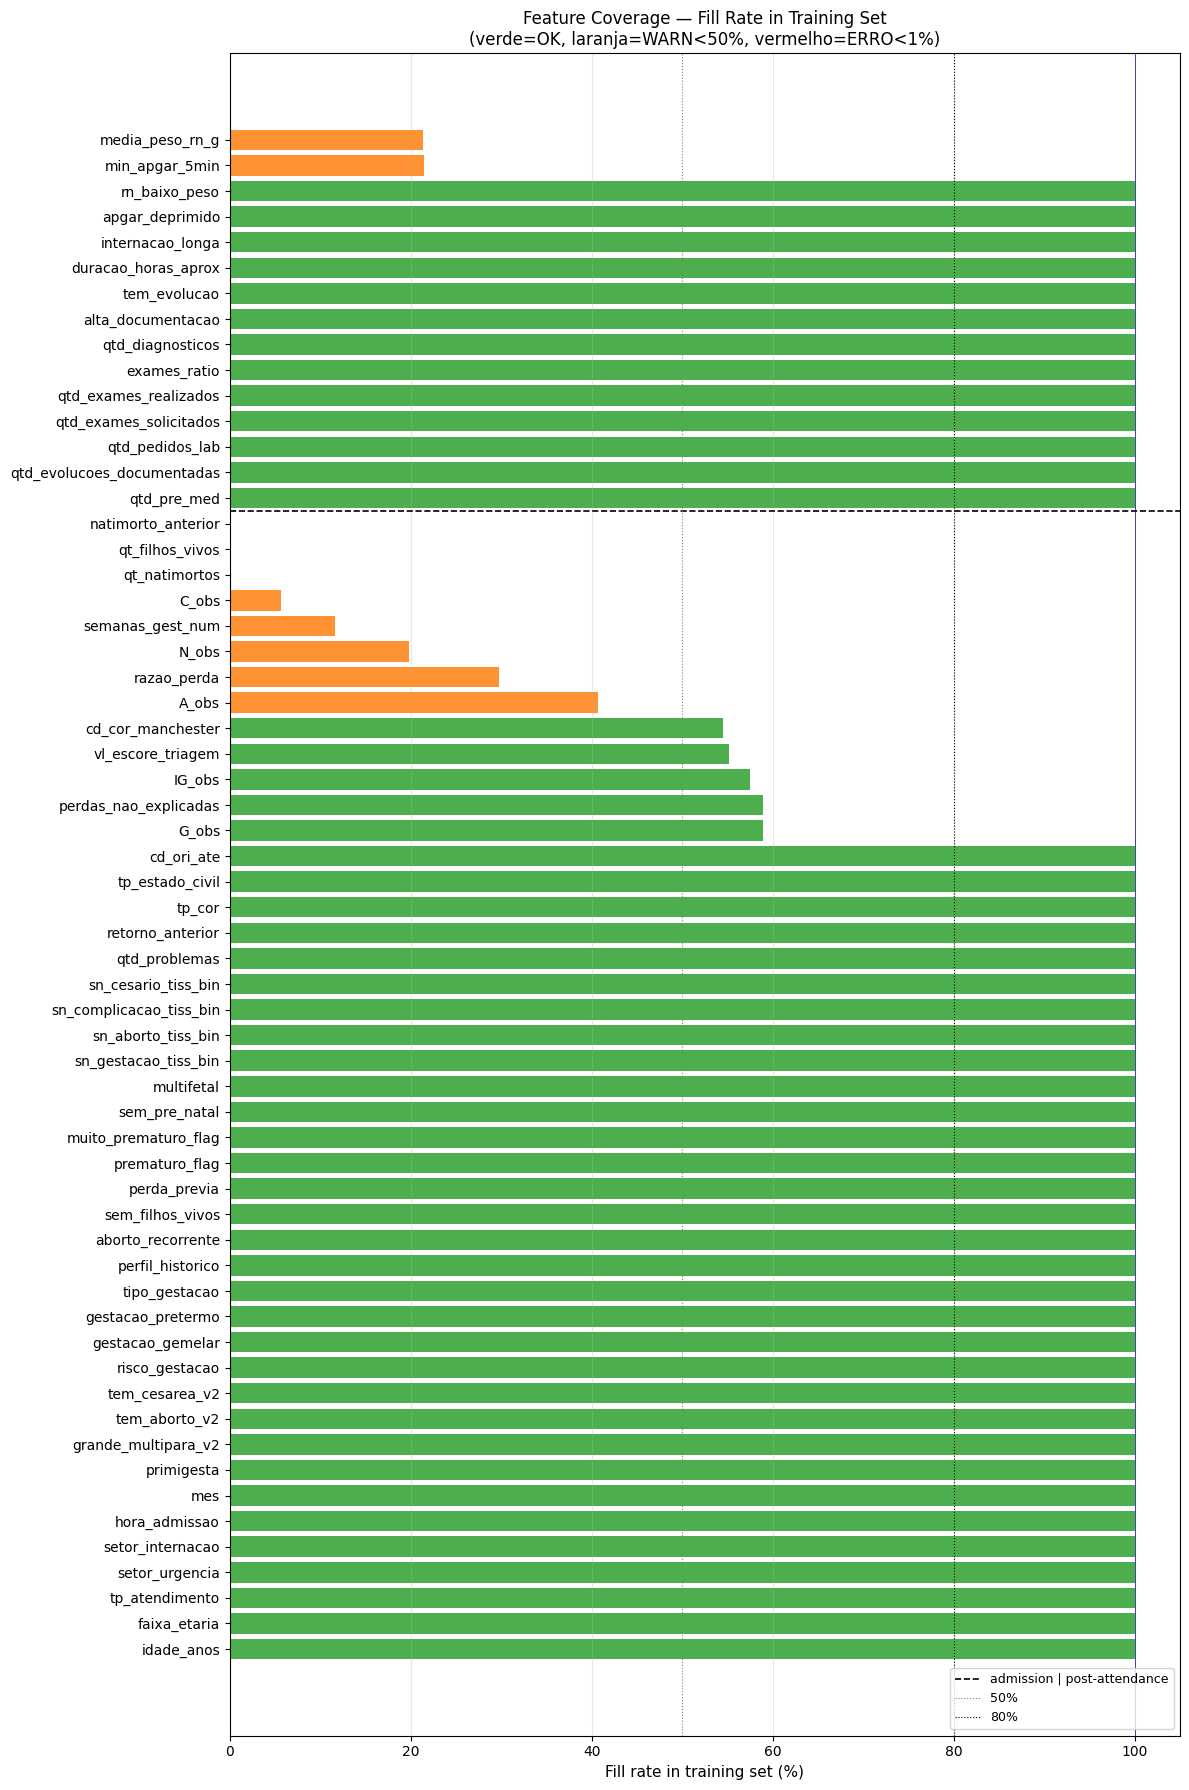

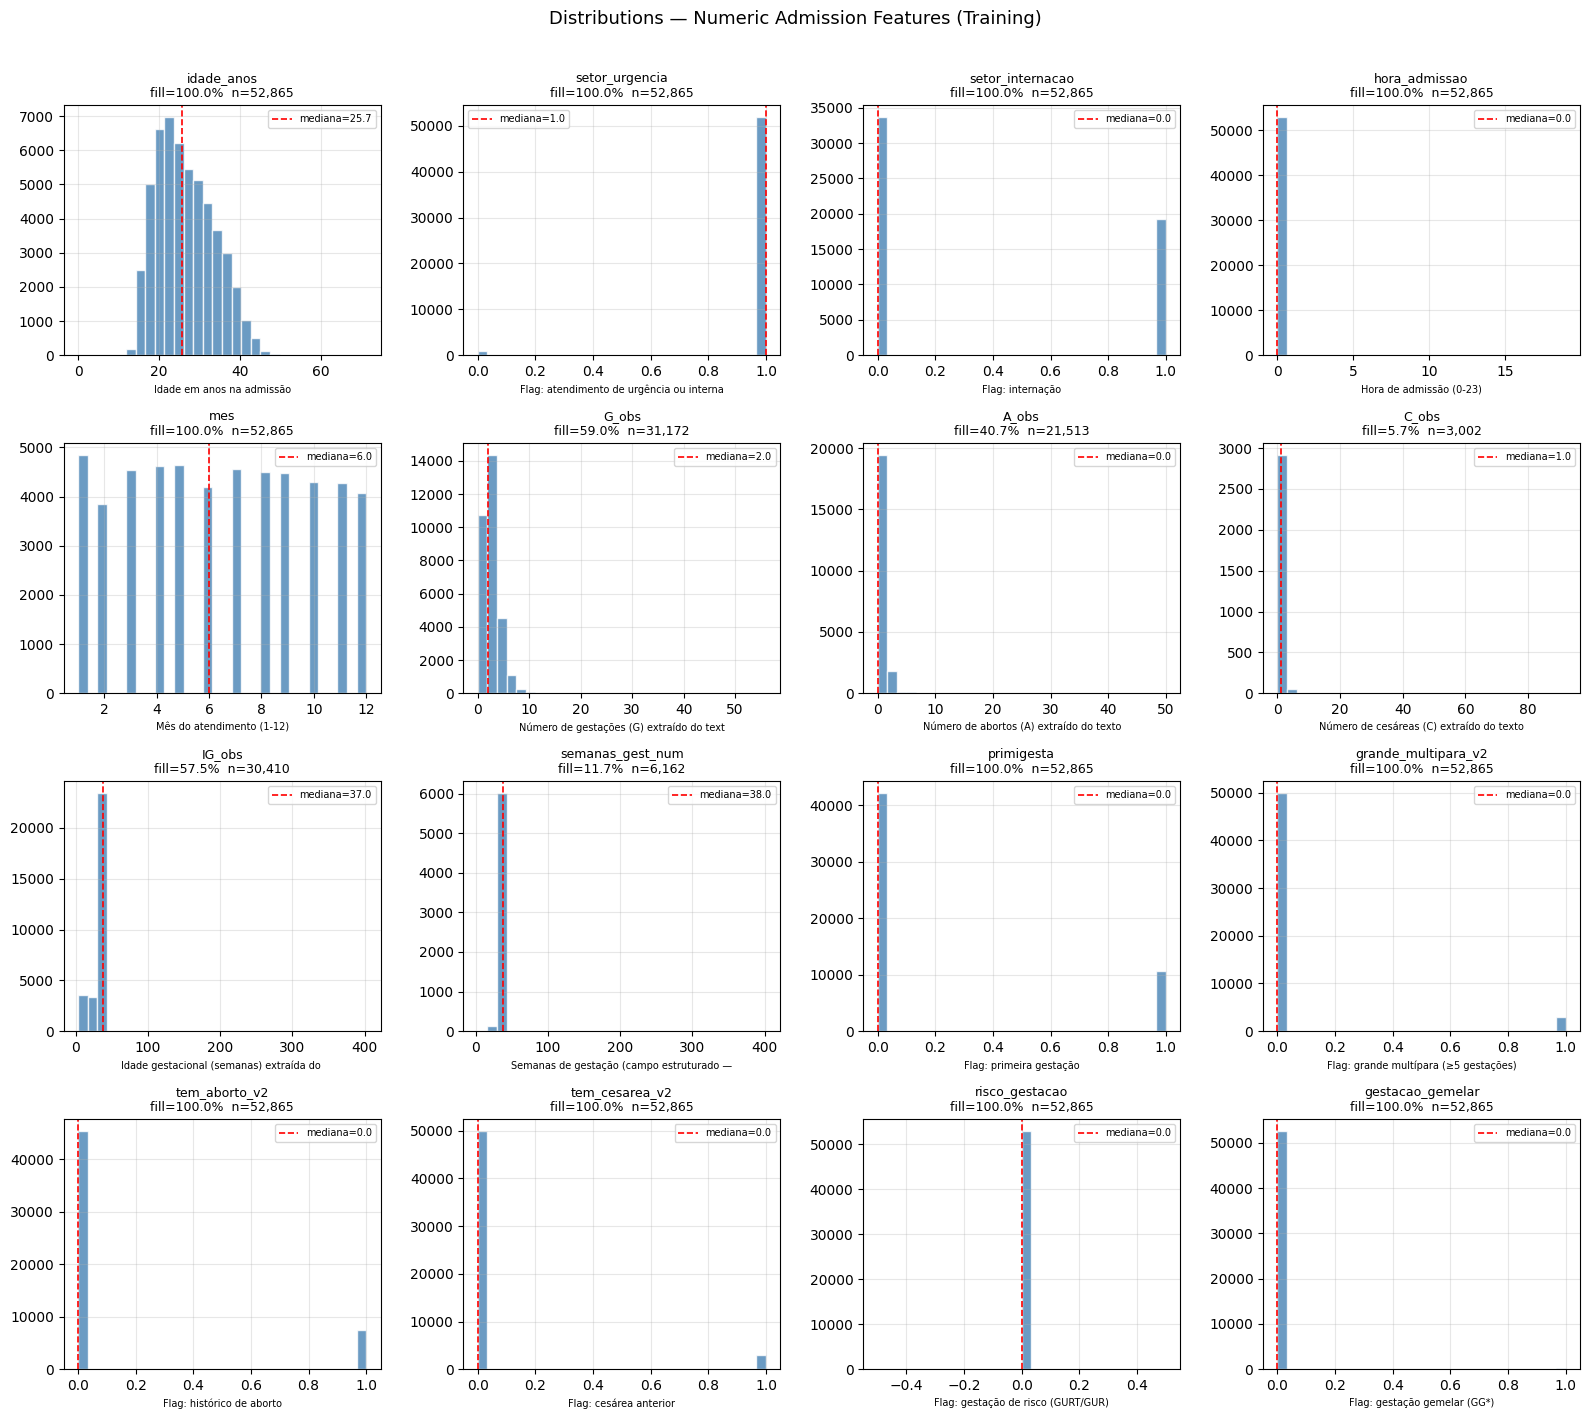

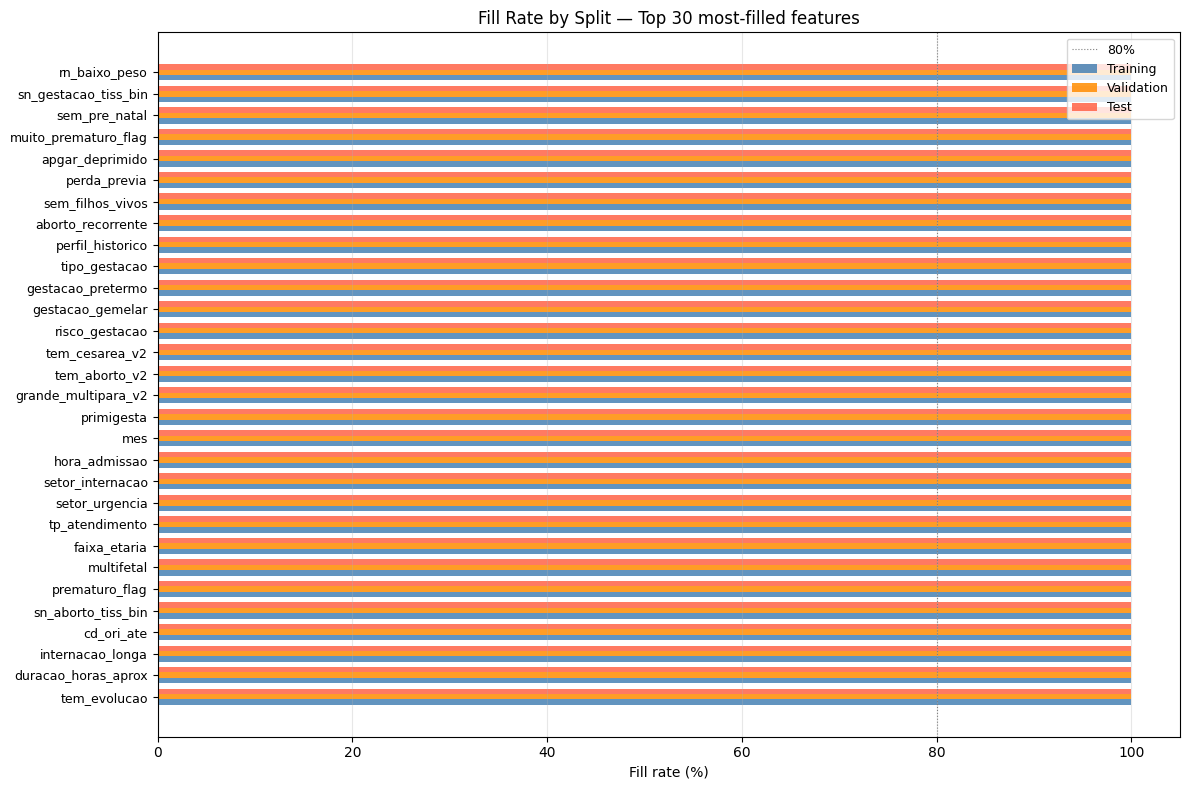

In [8]:
# ── Catálogo de rastreabilidade — feature → origem Oracle ─────────────────
#
# Colunas do catálogo:
#   oracle_table : tabela Oracle de origem
#   oracle_col   : coluna(s) de origem (pode ser múltiplas, separadas por " + ")
#   tipo         : estruturado | derivado_texto | derivado_calculo | tiss | triagem
#   momento      : admissao | pos_atendimento
#   descricao    : rótulo legível

FEATURE_CATALOG = {
    # ── Demográficas ─────────────────────────────────────────────────────
    "idade_anos":              {"oracle_table": "PACIENTE",              "oracle_col": "DT_NASCIMENTO → calc",         "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Idade em anos na admissão"},
    "faixa_etaria":            {"oracle_table": "PACIENTE",              "oracle_col": "DT_NASCIMENTO → bins",         "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Faixa etária (5 em 5 anos, início 5 — captura casos de abuso/gravidez precoce)"},
    # ── Setor / tipo de atendimento ───────────────────────────────────────
    "tp_atendimento":          {"oracle_table": "ATENDIME",              "oracle_col": "TP_ATENDIMENTO",               "tipo": "estruturado",      "momento": "admissao",          "descricao": "Tipo de atendimento (U=urgência, I=internação, A=ambulatório)"},
    "setor_urgencia":          {"oracle_table": "ATENDIME",              "oracle_col": "TP_ATENDIMENTO ∈ {U,I}",       "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: atendimento de urgência ou internação"},
    "setor_internacao":        {"oracle_table": "ATENDIME",              "oracle_col": "TP_ATENDIMENTO = I",           "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: internação"},
    "hora_admissao":           {"oracle_table": "ATENDIME",              "oracle_col": "DT_ATENDIMENTO (hora)",        "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Hora de admissão (0-23)"},
    "mes":                     {"oracle_table": "ATENDIME",              "oracle_col": "DT_ATENDIMENTO (mês)",         "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Mês do atendimento (1-12)"},
    # ── CID ───────────────────────────────────────────────────────────────
    "segmento_cid":            {"oracle_table": "DIAGNOSTICO_ATENDIME",  "oracle_col": "CD_CID → segmento",            "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Segmento de risco por CID principal"},
    # ── Obstétricas via texto livre (regex + LLM) ─────────────────────────
    "G_obs":                   {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "quadro_clinico → regex/LLM",   "tipo": "derivado_texto",   "momento": "admissao",          "descricao": "Número de gestações (G) extraído do texto"},
    "A_obs":                   {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "quadro_clinico → regex/LLM",   "tipo": "derivado_texto",   "momento": "admissao",          "descricao": "Número de abortos (A) extraído do texto"},
    "C_obs":                   {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "quadro_clinico → regex/LLM",   "tipo": "derivado_texto",   "momento": "admissao",          "descricao": "Número de cesáreas (C) extraído do texto"},
    "IG_obs":                  {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "quadro_clinico → regex/LLM",   "tipo": "derivado_texto",   "momento": "admissao",          "descricao": "Idade gestacional (semanas) extraída do texto"},
    "N_obs":                   {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "quadro_clinico → regex/LLM",   "tipo": "derivado_texto",   "momento": "admissao",          "descricao": "Nascidos vivos (N) extraído do texto"},
    "tipo_gestacao":           {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "quadro_clinico → regex/LLM",   "tipo": "derivado_texto",   "momento": "admissao",          "descricao": "Tipo: GUTT/GURT/GUPT/GGUT/etc."},
    "perfil_historico":        {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "G_obs/P_obs/A_obs → regra",    "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Perfil: PRIMIGESTA/MULTIPARA/ABORTO_RECORRENTE/etc."},
    "risco_gestacao":          {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "tipo_gestacao → regra",        "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: gestação de risco (GURT/GUR)"},
    "gestacao_gemelar":        {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "tipo_gestacao → regra",        "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: gestação gemelar (GG*)"},
    "gestacao_pretermo":       {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "tipo_gestacao/IG_obs → regra", "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: gestação pré-termo (IG<37 ou GUPT/GGPT)"},
    "primigesta":              {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "G_obs = 1",                    "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: primeira gestação"},
    "grande_multipara_v2":     {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "G_obs >= 5",                   "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: grande multípara (≥5 gestações)"},
    "tem_aborto_v2":           {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "A_obs >= 1",                   "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: histórico de aborto"},
    "tem_cesarea_v2":          {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "C_obs >= 1",                   "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: cesárea anterior"},
    "aborto_recorrente":       {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "A_obs >= 2",                   "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: aborto recorrente (≥2)"},
    "sem_filhos_vivos":        {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "G_obs>1 e N_obs=0",            "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: sem filhos vivos apesar de gestações prévias"},
    "perda_previa":            {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "A_obs>=1 ou sem_filhos_vivos", "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: perda gestacional prévia"},
    "perdas_nao_explicadas":   {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "G-P-C-A-1",                   "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Perdas não contabilizadas em G/P/A/C"},
    "razao_perda":             {"oracle_table": "ATENDIME/HISTORICO",    "oracle_col": "A_obs / (G_obs-1)",            "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Razão de perda: abortos / gestações prévias"},
    # ── Obstétricas estruturadas (ADMISSAO_CO — frequentemente NULL) ──────
    "semanas_gest_num":        {"oracle_table": "ADMISSAO_CO",           "oracle_col": "QT_SEMANAS",                   "tipo": "estruturado",      "momento": "admissao",          "descricao": "Semanas de gestação (campo estruturado — fallback de IG_obs)"},
    "qt_natimortos":           {"oracle_table": "ADMISSAO_CO",           "oracle_col": "QT_NATIMORTOS",                "tipo": "estruturado",      "momento": "admissao",          "descricao": "Quantidade de natimortos anteriores"},
    "qt_filhos_vivos":         {"oracle_table": "ADMISSAO_CO",           "oracle_col": "QT_FILHOS_VIVOS",              "tipo": "estruturado",      "momento": "admissao",          "descricao": "Quantidade de filhos vivos"},
    "prematuro_flag":          {"oracle_table": "ADMISSAO_CO",           "oracle_col": "QT_SEMANAS < 37",              "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: prematuro (IG < 37 semanas)"},
    "muito_prematuro_flag":    {"oracle_table": "ADMISSAO_CO",           "oracle_col": "QT_SEMANAS < 32",              "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: muito prematuro (IG < 32 semanas)"},
    "natimorto_anterior":      {"oracle_table": "ADMISSAO_CO",           "oracle_col": "QT_NATIMORTOS >= 1",           "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: natimorto anterior"},
    "sem_pre_natal":           {"oracle_table": "ADMISSAO_CO",           "oracle_col": "NR_CONSULTAS_PRE_NATAL = 0",   "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: sem pré-natal documentado"},
    "multifetal":              {"oracle_table": "RECEM_NASCIDO",         "oracle_col": "COUNT(*) > 1",                 "tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: gestação múltipla (>1 RN)"},
    # ── Flags TISS ────────────────────────────────────────────────────────
    "sn_gestacao_tiss_bin":    {"oracle_table": "ATENDIME",              "oracle_col": "SN_GESTACAO_TISS",             "tipo": "tiss",             "momento": "admissao",          "descricao": "TISS: gestante (S/N)"},
    "sn_aborto_tiss_bin":      {"oracle_table": "ATENDIME",              "oracle_col": "SN_ABORTO_TISS",               "tipo": "tiss",             "momento": "admissao",          "descricao": "TISS: aborto (S/N)"},
    "sn_complicacao_tiss_bin": {"oracle_table": "ATENDIME",              "oracle_col": "SN_COMPLICACAO_TISS",          "tipo": "tiss",             "momento": "admissao",          "descricao": "TISS: complicação gestacional (S/N)"},
    "sn_cesario_tiss_bin":     {"oracle_table": "ATENDIME",              "oracle_col": "SN_CESARIO_TISS",              "tipo": "tiss",             "momento": "admissao",          "descricao": "TISS: cesárea (S/N)"},
    # ── Triagem Manchester ────────────────────────────────────────────────
    "vl_escore_triagem":       {"oracle_table": "TRIAGEM_ATENDIMENTO",   "oracle_col": "VL_ESCORE_TRIAGEM",            "tipo": "triagem",          "momento": "admissao",          "descricao": "Escore de triagem Manchester (numérico)"},
    "cd_cor_manchester":       {"oracle_table": "TRIAGEM_ATENDIMENTO",   "oracle_col": "CD_COR_MANCHESTER",            "tipo": "triagem",          "momento": "admissao",          "descricao": "Cor Manchester: 1=vermelho … 5=azul"},
    # ── Comorbidades pré-existentes ───────────────────────────────────────
    "qtd_problemas":           {"oracle_table": "PW_PROBLEMA_PACIENTE",  "oracle_col": "COUNT(CD_PROBLEMA)",           "tipo": "estruturado",      "momento": "admissao",          "descricao": "Quantidade de problemas/comorbidades crônicos cadastrados"},
    # ── Histórico de retorno ───────────────────────────────────────────────
    "retorno_anterior":        {"oracle_table": "ATENDIME",              "oracle_col": "CD_ATENDIMENTO_PAI IS NOT NULL","tipo": "derivado_calculo", "momento": "admissao",          "descricao": "Flag: atendimento vinculado a retorno anterior"},
    # ── Sociodemográficas (adicionadas após análise de cobertura — 100% fill) ──
    "tp_cor":                  {"oracle_table": "PACIENTE",              "oracle_col": "TP_COR",                       "tipo": "estruturado",      "momento": "admissao",          "descricao": "Raça/etnia (R=Parda, B=Branca, P=Preta, A=Amarela, I=Indígena — IBGE)"},
    "tp_estado_civil":         {"oracle_table": "PACIENTE",              "oracle_col": "TP_ESTADO_CIVIL",              "tipo": "estruturado",      "momento": "admissao",          "descricao": "Estado civil — proxy de rede de suporte social pós-alta"},
    "cd_ori_ate":              {"oracle_table": "ATENDIME",              "oracle_col": "CD_ORI_ATE",                   "tipo": "estruturado",      "momento": "admissao",          "descricao": "Origem do atendimento (urgência espontânea, referência, retorno programado)"},
    # ── Pós-atendimento (leakage) ─────────────────────────────────────────
    "qtd_pre_med":             {"oracle_table": "PRESCRICAO/EVOLUCAO",   "oracle_col": "COUNT(prescrições)",           "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Quantidade de prescrições médicas durante internação"},
    "qtd_evolucoes_documentadas":{"oracle_table":"EVOLUCAO_ATENDIMENTO", "oracle_col": "COUNT(*)",                     "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Evoluções clínicas documentadas"},
    "qtd_pedidos_lab":         {"oracle_table": "ITPED_LAB",             "oracle_col": "COUNT(*)",                     "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Pedidos de exames laboratoriais"},
    "qtd_exames_solicitados":  {"oracle_table": "EXA_LAB",               "oracle_col": "COUNT(*)",                     "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Total de exames solicitados"},
    "qtd_exames_realizados":   {"oracle_table": "RES_EXA",               "oracle_col": "COUNT(*)",                     "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Total de exames com resultado"},
    "exames_ratio":            {"oracle_table": "EXA_LAB / RES_EXA",     "oracle_col": "realizados / (solicitados+1)", "tipo": "derivado_calculo", "momento": "pos_atendimento",   "descricao": "Taxa de realização de exames (0-1)"},
    "qtd_diagnosticos":        {"oracle_table": "DIAGNOSTICO_ATENDIME",  "oracle_col": "COUNT(CID)",                   "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Quantidade de diagnósticos registrados"},
    "alta_documentacao":       {"oracle_table": "EVOLUCAO_ATENDIMENTO",  "oracle_col": "COUNT(*) > 5",                 "tipo": "derivado_calculo", "momento": "pos_atendimento",   "descricao": "Flag: alta documentação (>5 evoluções)"},
    "tem_evolucao":            {"oracle_table": "EVOLUCAO_ATENDIMENTO",  "oracle_col": "COUNT(*) > 0",                 "tipo": "derivado_calculo", "momento": "pos_atendimento",   "descricao": "Flag: pelo menos uma evolução documentada"},
    "duracao_horas_aprox":     {"oracle_table": "ATENDIME",              "oracle_col": "DT_ALTA - DT_ATENDIMENTO",     "tipo": "derivado_calculo", "momento": "pos_atendimento",   "descricao": "Duração aproximada do atendimento em horas"},
    "internacao_longa":        {"oracle_table": "ATENDIME",              "oracle_col": "DT_ALTA - DT_ATENDIMENTO > 72h","tipo": "derivado_calculo","momento": "pos_atendimento",   "descricao": "Flag: internação longa (>72 horas)"},
    "media_peso_rn_g":         {"oracle_table": "RECEM_NASCIDO",         "oracle_col": "AVG(VL_PESO)",                 "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Peso médio do(s) RN (gramas)"},
    "min_apgar_5min":          {"oracle_table": "RECEM_NASCIDO",         "oracle_col": "MIN(VL_APGAR_5MIN)",           "tipo": "estruturado",      "momento": "pos_atendimento",   "descricao": "Menor APGAR aos 5 min entre os RN do parto"},
    "apgar_deprimido":         {"oracle_table": "RECEM_NASCIDO",         "oracle_col": "MIN(VL_APGAR_5MIN) < 7",       "tipo": "derivado_calculo", "momento": "pos_atendimento",   "descricao": "Flag: APGAR deprimido (<7) em algum RN"},
    "rn_baixo_peso":           {"oracle_table": "RECEM_NASCIDO",         "oracle_col": "QTD_RN_BAIXO_PESO > 0",        "tipo": "derivado_calculo", "momento": "pos_atendimento",   "descricao": "Flag: pelo menos um RN com baixo peso"},
}

# Ranges esperados para validação clínica de numéricas
RANGE_CLINICO = {
    "idade_anos":           (10,  60),
    "G_obs":                (1,   20),
    "A_obs":                (0,   10),
    "C_obs":                (0,   10),
    "IG_obs":               (6,   42),
    "N_obs":                (0,   15),
    "semanas_gest_num":     (6,   42),
    "qt_natimortos":        (0,   10),
    "qt_filhos_vivos":      (0,   15),
    "vl_escore_triagem":    (0,  100),
    "cd_cor_manchester":    (1,    5),
    "qtd_problemas":        (0,   50),
    "duracao_horas_aprox":  (0, 8760),  # até 1 ano
    "media_peso_rn_g":      (300, 6000),
    "min_apgar_5min":       (0,   10),
    "qtd_evolucoes_documentadas": (0, 500),
    "qtd_exames_solicitados":     (0, 200),
    "qtd_exames_realizados":      (0, 200),
}

# ── Loop de validação ──────────────────────────────────────────────────────
print("\n" + "=" * 90)
print("VALIDAÇÃO DAS VARIÁVEIS — COBERTURA E RASTREABILIDADE")
print("=" * 90)
print(f"{'Feature':<35} {'Momento':<16} {'Tipo':<20} {'Treino%':>8} {'Valid%':>8} {'Teste%':>8} {'Status':<8} {'Oracle'}")
print("-" * 130)

rows_valid = []
ALL_FEATURES_TO_VALIDATE = FEATURES_ADMISSAO + [
    f for f in FEATURES_POS_ATENDIMENTO if f not in FEATURES_ADMISSAO
]

for feat in ALL_FEATURES_TO_VALIDATE:
    cat = FEATURE_CATALOG.get(feat, {
        "oracle_table": "desconhecido",
        "oracle_col":   "?",
        "tipo":         "desconhecido",
        "momento":      "admissao",
        "descricao":    feat,
    })

    presente = feat in df.columns
    if not presente:
        status = "AUSENTE"
        fill_tr = fill_va = fill_te = 0.0
        dtype_str = "—"
        n_unique = 0
        min_val = max_val = median_val = np.nan
        out_of_range_pct = np.nan
        top_values = ""
        rows_valid.append({
            "feature": feat, "momento": cat["momento"], "tipo": cat["tipo"],
            "fill_treino": 0, "fill_valid": 0, "fill_teste": 0,
            "dtype": "—", "n_unique_treino": 0,
            "min_treino": np.nan, "median_treino": np.nan, "max_treino": np.nan,
            "pct_fora_range_clinico": np.nan,
            "top_valores": "", "status": status,
            "oracle_table": cat["oracle_table"], "oracle_col": cat["oracle_col"],
            "descricao": cat["descricao"],
        })
        print(f"  {'⛔ '+feat:<33} {cat['momento']:<16} {cat['tipo']:<20} {'—':>8} {'—':>8} {'—':>8} {status:<8} {cat['oracle_table']}.{cat['oracle_col']}")
        continue

    col_tr = pd.to_numeric(df_train[feat], errors="coerce") if pd.api.types.is_numeric_dtype(df_train[feat]) else df_train[feat]
    col_va = pd.to_numeric(df_valid[feat], errors="coerce") if pd.api.types.is_numeric_dtype(df_valid[feat]) else df_valid[feat]
    col_te = pd.to_numeric(df_test[feat],  errors="coerce") if pd.api.types.is_numeric_dtype(df_test[feat])  else df_test[feat]

    fill_tr = (1 - df_train[feat].isna().mean()) * 100
    fill_va = (1 - df_valid[feat].isna().mean()) * 100
    fill_te = (1 - df_test[feat].isna().mean())  * 100
    dtype_str = str(df[feat].dtype)
    n_unique  = int(df_train[feat].nunique())

    is_numeric = pd.api.types.is_numeric_dtype(df[feat])
    if is_numeric:
        s = pd.to_numeric(df_train[feat], errors="coerce").dropna()
        min_val    = round(s.min(), 3)    if len(s) > 0 else np.nan
        median_val = round(s.median(), 3) if len(s) > 0 else np.nan
        max_val    = round(s.max(), 3)    if len(s) > 0 else np.nan
        top_values = ""
        # Verifica range clínico
        if feat in RANGE_CLINICO:
            lo, hi = RANGE_CLINICO[feat]
            out_of_range_pct = round((((s < lo) | (s > hi)).sum() / len(s)) * 100, 2) if len(s) > 0 else 0.0
        else:
            out_of_range_pct = np.nan
    else:
        min_val = median_val = max_val = np.nan
        out_of_range_pct = np.nan
        vc = df_train[feat].value_counts().head(3)
        top_values = " | ".join([f"{v}:{c}" for v, c in vc.items()])

    # Status
    if fill_tr < 1:
        status = "ERRO"
    elif fill_tr < 50:
        status = "WARN"
    elif out_of_range_pct is not np.nan and not np.isnan(out_of_range_pct) and out_of_range_pct > 5:
        status = "RANGE"
    else:
        status = "OK"

    emoji = {"OK": "✅", "WARN": "⚠️ ", "ERRO": "❌", "RANGE": "📏"}.get(status, "  ")
    print(f"  {emoji+feat:<33} {cat['momento']:<16} {cat['tipo']:<20} "
          f"{fill_tr:>7.1f}% {fill_va:>7.1f}% {fill_te:>7.1f}%  {status:<8} "
          f"{cat['oracle_table']}")

    rows_valid.append({
        "feature": feat, "momento": cat["momento"], "tipo": cat["tipo"],
        "fill_treino": round(fill_tr, 2), "fill_valid": round(fill_va, 2), "fill_teste": round(fill_te, 2),
        "dtype": dtype_str, "n_unique_treino": n_unique,
        "min_treino": min_val, "median_treino": median_val, "max_treino": max_val,
        "pct_fora_range_clinico": out_of_range_pct,
        "top_valores": top_values, "status": status,
        "oracle_table": cat["oracle_table"], "oracle_col": cat["oracle_col"],
        "descricao": cat["descricao"],
    })

df_valid_report = pd.DataFrame(rows_valid)
df_valid_report.to_csv(OUT_DIR / "validacao_variaveis.csv", index=False)
print(f"\n  Salvo: validacao_variaveis.csv  ({len(df_valid_report)} features)")

# ── Resumo por status ──────────────────────────────────────────────────────
print("\n" + "=" * 50)
print("RESUMO DE STATUS")
print("=" * 50)
status_counts = df_valid_report["status"].value_counts()
for s, n in status_counts.items():
    emoji = {"OK": "✅", "WARN": "⚠️ ", "ERRO": "❌", "RANGE": "📏", "AUSENTE": "⛔"}.get(s, "  ")
    print(f"  {emoji} {s:<10}: {n:>3} features")

ausentes = df_valid_report[df_valid_report["status"] == "AUSENTE"]["feature"].tolist()
warns    = df_valid_report[df_valid_report["status"] == "WARN"]["feature"].tolist()
erros    = df_valid_report[df_valid_report["status"].isin(["ERRO","AUSENTE"])]["feature"].tolist()
if ausentes:
    print(f"\n  Ausentes do DataFrame (definidas mas não geradas): {ausentes}")
if warns:
    print(f"\n  Fill < 50% (usar com cautela): {warns}")

# ── Resumo por tabela Oracle ───────────────────────────────────────────────
print("\n" + "=" * 60)
print("RASTREABILIDADE — features por tabela Oracle")
print("=" * 60)
tab_oracle = (
    df_valid_report.groupby("oracle_table")
    .agg(
        n_features=("feature", "count"),
        fill_media_treino=("fill_treino", "mean"),
        n_ok=("status", lambda x: (x == "OK").sum()),
        n_warn=("status", lambda x: (x == "WARN").sum()),
        n_ausente=("status", lambda x: (x == "AUSENTE").sum()),
    )
    .sort_values("n_features", ascending=False)
    .round(1)
)
print(tab_oracle.to_string())
tab_oracle.to_csv(OUT_DIR / "rastreabilidade_oracle.csv")

# ── Plot 1: Fill rate por feature (barras horizontais) ────────────────────
df_plot = df_valid_report[df_valid_report["status"] != "AUSENTE"].copy()
df_plot = df_plot.sort_values(["momento", "fill_treino"], ascending=[True, False])

cores_status = {"OK": "#2ca02c", "WARN": "#ff7f0e", "ERRO": "#d62728", "RANGE": "#9467bd"}
fig_fill, ax_fill = plt.subplots(figsize=(12, max(8, len(df_plot) * 0.3)))
colors = [cores_status.get(s, "gray") for s in df_plot["status"]]
bars = ax_fill.barh(df_plot["feature"], df_plot["fill_treino"], color=colors, alpha=0.85)

# Linha divisória admissao / pos_atendimento
n_adm = (df_plot["momento"] == "admissao").sum()
ax_fill.axhline(n_adm - 0.5, color="black", ls="--", lw=1.2,
                label=f"{T['fill_adm_lbl']} | {T['fill_pos_lbl']}")
ax_fill.axvline(50,  color="gray",  ls=":", lw=0.8, label=T["fill_50_lbl"])
ax_fill.axvline(80,  color="black", ls=":", lw=0.8, label=T["fill_80_lbl"])
ax_fill.axvline(100, color="navy",  ls="-", lw=0.5)
ax_fill.set_xlabel(T["fill_ylabel"], fontsize=11)
ax_fill.set_title(T["fill_title_fmt"].format(
    extra="(verde=OK, laranja=WARN<50%, vermelho=ERRO<1%)"), fontsize=12)
ax_fill.legend(fontsize=9, loc="lower right")
ax_fill.set_xlim(0, 105)
ax_fill.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "00_fill_rate_features.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print("  Gerado: plots/00_fill_rate_features.png")

# ── Plot 2: Distribuição das features numéricas de admissão ───────────────
feats_num_adm = [
    f for f in FEATURES_ADMISSAO
    if f in df.columns and pd.api.types.is_numeric_dtype(df[f])
    and df_train[f].notna().sum() > 100
][:16]  # máx 16 para caber num grid 4×4

if feats_num_adm:
    ncols = 4
    nrows = (len(feats_num_adm) + ncols - 1) // ncols
    fig_dist, axes_dist = plt.subplots(nrows, ncols, figsize=(16, nrows * 3.5))
    axes_dist = axes_dist.ravel()
    for i, feat in enumerate(feats_num_adm):
        ax = axes_dist[i]
        vals = pd.to_numeric(df_train[feat], errors="coerce").dropna()
        cat  = FEATURE_CATALOG.get(feat, {})
        ax.hist(vals, bins=30, color="steelblue", edgecolor="white", alpha=0.8)
        med = vals.median()
        ax.axvline(med, color="red", ls="--", lw=1.2, label=f"mediana={med:.1f}")
        fill = round((1 - df_train[feat].isna().mean()) * 100, 1)
        ax.set_title(f"{feat}\nfill={fill}%  n={len(vals):,}", fontsize=9)
        ax.set_xlabel(cat.get("descricao", feat)[:40], fontsize=7)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
    for j in range(len(feats_num_adm), len(axes_dist)):
        axes_dist[j].set_visible(False)
    plt.suptitle(T["dist_title"], fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "00b_distribuicoes_numericas_admissao.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: plots/00b_distribuicoes_numericas_admissao.png")

# ── Plot 3: Fill rate comparativo treino / validação / teste ──────────────
df_comp = df_valid_report[df_valid_report["status"] != "AUSENTE"].copy()
df_comp = df_comp.sort_values("fill_treino", ascending=True).tail(30)  # top 30

fig_comp, ax_comp = plt.subplots(figsize=(12, 8))
y = np.arange(len(df_comp))
ax_comp.barh(y - 0.25, df_comp["fill_treino"], height=0.25, color="steelblue",  label=T["split_treino"], alpha=0.85)
ax_comp.barh(y,        df_comp["fill_valid"],  height=0.25, color="darkorange", label=T["split_valid"],  alpha=0.85)
ax_comp.barh(y + 0.25, df_comp["fill_teste"],  height=0.25, color="tomato",     label=T["split_teste"],  alpha=0.85)
ax_comp.set_yticks(y); ax_comp.set_yticklabels(df_comp["feature"], fontsize=9)
ax_comp.set_xlabel(T["split_ylabel"]); ax_comp.set_title(T["split_title"])
ax_comp.axvline(80, color="gray", ls=":", lw=0.8, label=T["split_80_lbl"])
ax_comp.legend(fontsize=9); ax_comp.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "00c_fill_rate_por_split.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print("  Gerado: plots/00c_fill_rate_por_split.png")

print(f"\n[03.1 - Validação] {len(df_valid_report)} features validadas | "
      f"{(df_valid_report['status']=='OK').sum()} OK | "
      f"{(df_valid_report['status']=='WARN').sum()} WARN | "
      f"{(df_valid_report['status'].isin(['ERRO','AUSENTE'])).sum()} ERRO/AUSENTE")

## 5. Preprocessamento — MICE Imputation

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    """Preprocessador com MICE (IterativeImputer) para numéricas e OHE para categóricas."""
    num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat_cols = [c for c in X.columns if c not in num_cols]

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imp", IterativeImputer(max_iter=10, random_state=42, min_value=0)),
                ("sc",  StandardScaler()),
            ]), num_cols),
            ("cat", Pipeline([
                ("imp", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), cat_cols),
        ],
        remainder="drop",
    )


X_train = df_train[FEATURES]
X_valid = df_valid[FEATURES]
X_test  = df_test[FEATURES]

preproc = build_preprocessor(X_train)
X_train_t = preproc.fit_transform(X_train)
X_valid_t = preproc.transform(X_valid)
X_test_t  = preproc.transform(X_test)

print(f"Shape após preprocessamento (FEATURES_ADMISSAO): {X_train_t.shape}")

# Preprocessador para features completas (análise de leakage)
X_train_all = df_train[FEATURES_ALL]
X_valid_all = df_valid[FEATURES_ALL]
X_test_all  = df_test[FEATURES_ALL]

preproc_all = build_preprocessor(X_train_all)
X_train_all_t = preproc_all.fit_transform(X_train_all)
X_valid_all_t = preproc_all.transform(X_valid_all)
X_test_all_t  = preproc_all.transform(X_test_all)

print(f"Shape após preprocessamento (FEATURES_ALL): {X_train_all_t.shape}")

# ── Feature names após preprocessamento ────────────────────────────────────
TARGET_PRINCIPAL = "y_retorno_30d"
y_train = df_train[TARGET_PRINCIPAL].values
y_valid = df_valid[TARGET_PRINCIPAL].values
y_test  = df_test[TARGET_PRINCIPAL].values

try:
    feat_names = list(preproc.get_feature_names_out())
    feat_names = [n.split("__", 1)[-1] for n in feat_names]
except AttributeError:
    num_cols_fn = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
    cat_cols_fn = [c for c in X_train.columns if c not in num_cols_fn]
    ohe_fn = preproc.named_transformers_["cat"]["ohe"]
    feat_names = num_cols_fn + list(ohe_fn.get_feature_names_out(cat_cols_fn))

print(f"\nFeature names após preprocessamento: {len(feat_names)} features")

## Salvar Artefatos

In [10]:
splits_artifact = {
    "df_train":      df_train,
    "df_valid":      df_valid,
    "df_test":       df_test,
    "y_train":       y_train,
    "y_valid":       y_valid,
    "y_test":        y_test,
    "X_train_t":     X_train_t,
    "X_valid_t":     X_valid_t,
    "X_test_t":      X_test_t,
    "X_train":       X_train,
    "X_valid":       X_valid,
    "X_test":        X_test,
    "X_train_all":   X_train_all,
    "X_valid_all":   X_valid_all,
    "X_test_all":    X_test_all,
    "X_train_all_t": X_train_all_t,
    "X_valid_all_t": X_valid_all_t,
    "X_test_all_t":  X_test_all_t,
}

with open(ART_DIR / "splits.pkl", "wb") as f:
    pickle.dump(splits_artifact, f)

features_artifact = {
    "FEATURES":                 FEATURES,
    "FEATURES_ADMISSAO":        FEATURES_ADMISSAO,
    "FEATURES_POS_ATENDIMENTO": FEATURES_POS_ATENDIMENTO,
    "FEATURES_ALL":             FEATURES_ALL,
    "FEATURES_ADM_PRESENT":     FEATURES_ADM_PRESENT,
    "FEATURES_POS_PRESENT":     FEATURES_POS_PRESENT,
    "TARGET_PRINCIPAL":         TARGET_PRINCIPAL,
    "THRESHOLD":                0.30,
    "TARGETS":                  TARGETS,
}
with open(ART_DIR / "features.json", "w", encoding="utf-8") as f:
    json.dump(features_artifact, f, ensure_ascii=False, indent=2)

with open(ART_DIR / "preprocessor.pkl", "wb") as f:
    pickle.dump({"preproc": preproc, "preproc_all": preproc_all}, f)

with open(ART_DIR / "feat_names.json", "w", encoding="utf-8") as f:
    json.dump(feat_names, f, ensure_ascii=False, indent=2)

print(f"\n[03.1] Artefatos salvos em: {ART_DIR}")
print(f"\n[03.1] Concluído. Outputs: {OUT_DIR}")